# Experiment 1b: making the $N^3$ mesh failure visible

On a perfectly uniform $\psi_2=\log h$ grid, the $N^3$ regime can still select the correct bandwidth because its largest surviving nearest-neighbor similarity occurs near $\arg\min_h\widehat Q_n(h)$. This experiment tests whether that selection is robust to a small local mesh irregularity.

One point in an otherwise uniform grid is moved toward its left neighbor near $h=0.7$, far from the continuous prediction $h_\infty$. The endpoints, number of candidates, sample, bandwidth family, and all other grid points remain fixed. A resolved continuous kernel should be comparatively insensitive to this isolated close pair. An unresolved nearest-neighbor kernel may lock onto it.

**Scope.** This is a robustness stress test, not a counterexample under the theorem's exact uniform-grid assumptions.

In [1]:
from __future__ import annotations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize_scalar

from kde_tools import (
    bandwidth_grid_linear_in_psi_beta,
    nearest_bandwidth_grid_index,
    perron_vector,
)
from kde_tools.fourier import beta2_divergence_matrix_fft

SEED = 20260902
N_DATA = 200
N = 400
H_MIN, H_MAX = 0.05, 1.0
TARGET_H = 0.70
FFT_HALF_WIDTH = 10.0
FFT_SPATIAL_POINTS = 2048

rng = np.random.default_rng(SEED)
samples = rng.normal(size=N_DATA)
squared_differences = (
    samples[:, None] - samples[None, :]
) ** 2

def local_beta2_log_metric(h):
    q = 2.0 * float(h) ** 2
    d = squared_differences
    overlap = np.exp(-d / (2.0 * q)) / np.sqrt(
        2.0 * np.pi * q
    )
    second_q_factor = (
        3.0 / (4.0 * q**2)
        - 3.0 * d / (2.0 * q**3)
        + d**2 / (4.0 * q**4)
    )
    return float(
        2.0 * h**4
        * np.mean(overlap * second_q_factor)
    )

continuous_minimum = minimize_scalar(
    local_beta2_log_metric,
    bounds=(H_MIN, H_MAX),
    method="bounded",
    options={"xatol": 1e-12},
)
h_infinity = float(continuous_minimum.x)
print(
    f"N={N}, fixed sample n={N_DATA}, "
    f"h_infinity={h_infinity:.8f}"
)

N=400, fixed sample n=200, h_infinity=0.24175622


In [2]:
LAMBDA_RULES = {
    r"$N^{1/2}$": lambda N: N**0.5,
    r"$N$": lambda N: float(N),
    r"$N^{3/2}$": lambda N: N**1.5,
    r"$1$": lambda N: 1.0,
    r"$N^2$": lambda N: float(N**2),
    r"$N^3$": lambda N: float(N**3),
}
COLORS = dict(zip(
    LAMBDA_RULES,
    ["#0072B2", "#009E73", "#CC79A7",
     "#E69F00", "#7A7A7A", "#D55E00"],
))
GAP_FRACTIONS = np.array([
    1.00, 0.90, 0.75, 0.60, 0.50, 0.40,
    0.35, 0.30, 0.25, 0.20, 0.15, 0.10,
])

base_grid = bandwidth_grid_linear_in_psi_beta(
    H_MIN, H_MAX, beta=2.0, grid_size=N
)
base_psi = np.log(base_grid)
delta_psi = base_psi[1] - base_psi[0]
close_pair_left = int(
    np.argmin(np.abs(base_grid - TARGET_H))
)
close_pair_left = min(close_pair_left, N - 2)

rows = []
n3_profiles = {}

for gap_fraction in GAP_FRACTIONS:
    perturbed_psi = base_psi.copy()
    perturbed_psi[close_pair_left + 1] = (
        perturbed_psi[close_pair_left]
        + gap_fraction * delta_psi
    )
    h_grid = np.exp(perturbed_psi)
    divergence = beta2_divergence_matrix_fft(
        samples,
        h_grid,
        half_width=FFT_HALF_WIDTH,
        spatial_points=FFT_SPATIAL_POINTS,
    )

    for regime, lambda_rule in LAMBDA_RULES.items():
        lambda_value = float(lambda_rule(N))
        similarity = np.exp(-lambda_value * divergence)
        np.fill_diagonal(similarity, 1.0)
        vector = perron_vector(similarity)
        selected_index = int(np.argmax(vector))

        rows.append({
            "gap_fraction": gap_fraction,
            "regime": regime,
            "selected_h": float(
                h_grid[selected_index]
            ),
            "selected_index": selected_index,
            "close_pair_h_left": float(
                h_grid[close_pair_left]
            ),
            "close_pair_h_right": float(
                h_grid[close_pair_left + 1]
            ),
            "close_pair_similarity": float(
                similarity[
                    close_pair_left,
                    close_pair_left + 1,
                ]
            ),
        })

        if (
            regime == r"$N^3$"
            and gap_fraction in {1.0, 0.2}
        ):
            n3_profiles[gap_fraction] = (
                h_grid.copy(), vector.copy()
            )

stress_results = pd.DataFrame(rows)
stress_results["regime"] = pd.Categorical(
    stress_results["regime"],
    categories=list(LAMBDA_RULES),
    ordered=True,
)

selected_table = stress_results.pivot(
    index="gap_fraction",
    columns="regime",
    values="selected_h",
)
display(
    selected_table.loc[[1.0, 0.4, 0.3, 0.2, 0.1]]
    .round(6)
)

regime,$N^{1/2}$,$N$,$N^{3/2}$,$1$,$N^2$,$N^3$
gap_fraction,,,,,,
1.0,0.255004,0.23656,0.241948,0.262779,0.241948,0.241948
0.4,0.255004,0.23656,0.241948,0.262779,0.241948,0.241948
0.3,0.255004,0.23656,0.241948,0.262779,0.241948,0.698978
0.2,0.255004,0.23656,0.241948,0.262779,0.241948,0.698453
0.1,0.255004,0.23656,0.241948,0.262779,0.241948,0.697405


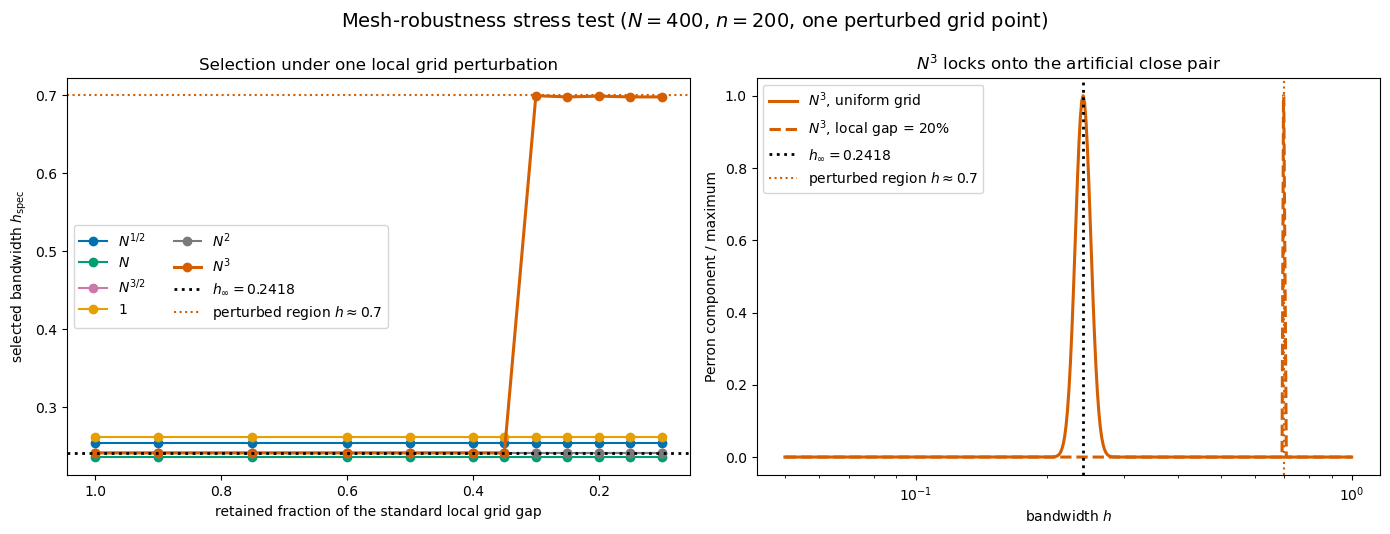

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))

for regime in LAMBDA_RULES:
    subset = stress_results[
        stress_results["regime"] == regime
    ].sort_values("gap_fraction", ascending=False)
    axes[0].plot(
        subset["gap_fraction"],
        subset["selected_h"],
        marker="o",
        linewidth=2.2 if regime == r"$N^3$" else 1.5,
        color=COLORS[regime],
        label=regime,
    )

axes[0].axhline(
    h_infinity,
    color="black",
    linestyle=":",
    linewidth=2.0,
    label=rf"$h_\infty={h_infinity:.4f}$",
)
axes[0].axhline(
    TARGET_H,
    color="#D55E00",
    linestyle=":",
    linewidth=1.5,
    label=rf"perturbed region $h\approx{TARGET_H}$",
)
axes[0].invert_xaxis()
axes[0].set(
    xlabel="retained fraction of the standard local grid gap",
    ylabel=r"selected bandwidth $h_{\mathrm{spec}}$",
    title="Selection under one local grid perturbation",
)
axes[0].legend(ncol=2)

for gap_fraction, linestyle in [(1.0, "-"), (0.2, "--")]:
    h_grid, vector = n3_profiles[gap_fraction]
    axes[1].plot(
        h_grid,
        vector / vector.max(),
        color=COLORS[r"$N^3$"],
        linestyle=linestyle,
        linewidth=2.2,
        label=(
            r"$N^3$, uniform grid"
            if gap_fraction == 1.0
            else r"$N^3$, local gap = 20%"
        ),
    )
axes[1].axvline(
    h_infinity,
    color="black",
    linestyle=":",
    linewidth=2.0,
    label=rf"$h_\infty={h_infinity:.4f}$",
)
axes[1].axvline(
    TARGET_H,
    color="#D55E00",
    linestyle=":",
    linewidth=1.5,
    label=rf"perturbed region $h\approx{TARGET_H}$",
)
axes[1].set(
    xscale="log",
    xlabel=r"bandwidth $h$",
    ylabel="Perron component / maximum",
    title=r"$N^3$ locks onto the artificial close pair",
)
axes[1].legend()

fig.suptitle(
    rf"Mesh-robustness stress test ($N={N}$, "
    rf"$n={N_DATA}$, one perturbed grid point)",
    fontsize=14,
)
fig.tight_layout()
plt.show()

## Result

On the uniform grid, the $N^3$ selector is close to $h_\infty$. Once the isolated gap near $h=0.7$ is reduced to about 30% of the standard gap, the $N^3$ Perron vector moves to that artificial close pair and the selected bandwidth becomes approximately $0.7$. The admissible regimes remain near their original selections over the same perturbations.

The mechanism is exponential amplification:

$$D_{i,i+1}\approx \widehat Q_n(h_i)(\Delta\psi_i)^2,
\qquad S_{i,i+1}=\exp(-N^3D_{i,i+1}).$$

Reducing one gap by a factor $r$ reduces its local divergence by approximately $r^2$. In the unresolved $N^3$ regime, this can make that pair overwhelmingly more connected than every ordinary neighboring pair, even though it is far from the minimum of $\widehat Q_n$.

This demonstrates a concrete failure of **mesh robustness**. It does not show inconsistency on the exact uniform grid; rather, it shows why an apparently correct $N^3$ argmax is produced by a fragile nearest-neighbor mechanism instead of a resolved continuous-kernel approximation.